# Milestone 3, Part 4.3: Adaptation experiment

We start from our deployed model **v1** (Milestone 2), change the data, update the model, and compare before vs after.

* **a.** Real drift: do the test months (May to Oct 2026) look different from validation (Jan to Apr)?
* **b.** Simulated drift 1: fewer same-story pairs (class prior shift)
* **c.** Simulated drift 2: a new language (English-only model sees French)
* **d.** Updating v1 with new labels from May to Jul
* **e.** Latency and size before vs after

Helper functions are in `src/adaptation.py`, results go to `outputs/milestone3/adaptation/`. Trained models are saved in
`models/exp/adaptation` (not in git). `SMOKE=1` runs a quick small version.

In [1]:
import json, os, platform, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil, torch, sentence_transformers
from sklearn.linear_model import LogisticRegression

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'pairs').is_dir())
sys.path.insert(0, str(ROOT))
import src.robustness as m3
from src.robustness import (load_pairs, Pipeline, BiEncoder, evaluate, bootstrap_ci, ece, best_threshold, front_pages,
                            page_latency, load_m2, V1_PATH, BASE_MODEL, SEED)
import src.adaptation as ad
from src.adaptation import *

SMOKE = os.environ.get('SMOKE', '0') == '1'
O = OUT / 'smoke' if SMOKE else OUT
(O / 'figures').mkdir(parents=True, exist_ok=True)
MD = ADAPT_MODELS / 'smoke' if SMOKE else ADAPT_MODELS
MD.mkdir(parents=True, exist_ok=True)
SEEDS = [SEED] if SMOKE else [SEED, SEED + 1, SEED + 2]
TRAIN_DEVICE = m3.DEVICE

M2 = load_m2()                                    # same recipe as Milestone 2 and Section 2
if M2['config']:
    m3.CFG = {**m3.CFG, **M2['config']}
P = load_pairs()
TRAIN, VAL, TEST = P['train'], P['val'], P['test']
if SMOKE:
    TRAIN = TRAIN.sample(800, random_state=SEED).reset_index(drop=True)
    VAL = VAL.sample(400, random_state=SEED).reset_index(drop=True)
    TEST = TEST.sample(700, random_state=SEED).reset_index(drop=True)
    m3.CFG = {**m3.CFG, 'epochs': 1}
for d in (TRAIN, VAL, TEST):
    d['month'] = month(d)
ADAPT_WIN = TEST[TEST.month <= '202607'].reset_index(drop=True)   # May-Jul: labels arrive
FUTURE = TEST[TEST.month >= '202608'].reset_index(drop=True)      # Aug-Oct: evaluated after the update

HW = {'train_device': TRAIN_DEVICE, 'cpu': platform.processor() or platform.machine(), 'threads': torch.get_num_threads(),
      'torch': torch.__version__, 'sentence_transformers': sentence_transformers.__version__, 'smoke': SMOKE}
try:
    import subprocess
    HW['cpu'] = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip() or HW['cpu']
except Exception:
    pass
print(HW)
print('recipe:', m3.CFG)
print({k: len(v) for k, v in dict(train=TRAIN, val=VAL, test=TEST, adapt_window=ADAPT_WIN, future=FUTURE).items()})

C_BEFORE, C_AFTER, C_ALT, C_REF = '#1d3557', '#e07a5f', '#7b5ea7', '#9aa5b1'   # v1 navy / adapted orange (as in Section 2)

W1113 09:40:33.215000 69430 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


{'train_device': 'mps', 'cpu': 'Apple M4 Max', 'threads': 10, 'torch': '2.15.0', 'sentence_transformers': '6.3.0', 'smoke': False}
recipe: {'epochs': 3, 'batch_size': 32, 'learning_rate': 2e-05, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'max_grad_norm': 1.0, 'max_seq_length': 128, 'margin': 0.5, 'freeze_word_embeddings': True, 'patience': 1}
{'train': 21907, 'val': 2850, 'test': 2457, 'adapt_window': 1393, 'future': 1064}


In [2]:
v1 = Pipeline(BiEncoder(V1_PATH, 'v1')).fit(VAL)
print('v1 val threshold:', round(v1.threshold, 4))
if not SMOKE:
    assert abs(v1.threshold - 0.7244) < 1e-3, 'models/minilm_finetuned is not the Milestone 2 model'

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14475.66it/s]

v1 val threshold: 0.7244


## a. Real drift (May to Oct 2026)

We compare each test month to validation (Jan to Apr) with PSI, and check if F1 drops. Our triggers (from 4.1):

* **T1:** PSI > 0.2 on at least 2 of 4 features
* **T2:** F1 more than 0.03 below validation for 2 months in a row
* **T3:** estimated same-story rate changes by more than 0.10

In [3]:
vocab = vocabulary(TRAIN)
REF = reference_stats(v1, VAL, vocab)
rows = [drift_row(v1, VAL, REF, vocab, 'reference (val, Jan-Apr)')]
for mo, g in TEST.groupby('month'):
    rows.append(drift_row(v1, g.reset_index(drop=True), REF, vocab, mo))
drift = pd.DataFrame(rows)

T_PSI, K_FEAT, M_F1, N_WIN, T_PRIOR = 0.2, 2, 0.03, 2, 0.10
PSI_COLS = ['psi_score', 'psi_words', 'psi_oov', 'psi_edition']
drift['n_psi_over'] = (drift[PSI_COLS] > T_PSI).sum(axis=1)
drift['T1_drift'] = drift.n_psi_over >= K_FEAT
below = (drift.f1 < REF['f1'] - M_F1).astype(int)
drift['T2_decay'] = (below.rolling(N_WIN).sum() >= N_WIN).fillna(False).astype(bool)
drift['T3_prior'] = (drift.est_same_rate - drift.loc[0, 'true_same_rate']).abs() > T_PRIOR
drift.loc[0, ['T1_drift', 'T2_decay', 'T3_prior']] = False
drift.to_csv(O / 'drift_by_month.csv', index=False)
print('reference F1', round(REF['f1'], 4), '| trigger fired in:',
      {t: drift.loc[drift[t], 'window'].tolist() for t in ['T1_drift', 'T2_decay', 'T3_prior']})
drift[['window', 'pairs', 'french_share', 'psi_edition', 'psi_words', 'psi_oov', 'psi_score', 'est_same_rate',
       'true_same_rate', 'f1', 'pr_auc', 'T1_drift', 'T2_decay', 'T3_prior']].round(3)

reference F1 0.8823 | trigger fired in: {'T1_drift': [], 'T2_decay': [], 'T3_prior': []}


,window,pairs,french_share,psi_edition,psi_words,psi_oov,psi_score,est_same_rate,true_same_rate,f1,pr_auc,T1_drift,T2_decay,T3_prior
0,"reference (val, Jan-Apr)",2850,0.479,0.000,0.000,0.000,0.000,0.453,0.453,0.882,0.944,False,False,False
1,202605,623,0.433,0.009,0.139,0.109,0.105,0.428,0.467,0.904,0.981,False,False,False
2,202606,376,0.000,4.374,0.197,0.058,0.174,0.444,0.447,0.943,0.991,False,False,False
3,202607,394,0.228,0.285,0.139,0.068,0.164,0.493,0.472,0.883,0.931,False,False,False
4,202608,422,0.109,0.747,0.040,0.097,0.167,0.449,0.469,0.899,0.958,False,False,False
5,202609,428,0.238,0.260,0.140,0.126,0.079,0.491,0.477,0.888,0.947,False,False,False
6,202610,214,0.449,0.004,0.148,0.165,0.013,0.497,0.477,0.942,0.982,False,False,False


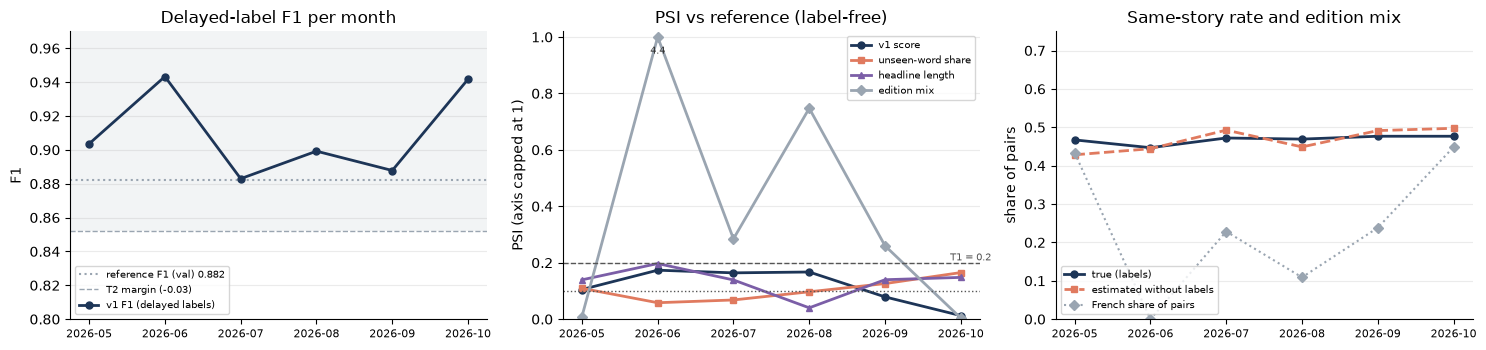

In [4]:
d = drift.iloc[1:]
x = np.arange(len(d)); labels = [f'{w[:4]}-{w[4:]}' for w in d.window]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
ax = axes[0]
ax.axhspan(REF['f1'] - M_F1, REF['f1'] + 1, color=C_REF, alpha=0.12, lw=0)
ax.axhline(REF['f1'], color=C_REF, ls=':', lw=1.5, label=f"reference F1 (val) {REF['f1']:.3f}")
ax.axhline(REF['f1'] - M_F1, color=C_REF, ls='--', lw=1, label=f'T2 margin (-{M_F1})')
ax.plot(x, d.f1, color=C_BEFORE, marker='o', ms=5, lw=2, label='v1 F1 (delayed labels)')
ax.set(title='Delayed-label F1 per month', ylabel='F1', ylim=(0.80, 0.97)); ax.legend(fontsize=7, loc='lower left')
ax = axes[1]
for col, c, mk, lab in [('psi_score', C_BEFORE, 'o', 'v1 score'), ('psi_oov', C_AFTER, 's', 'unseen-word share'),
                        ('psi_words', C_ALT, '^', 'headline length'), ('psi_edition', C_REF, 'D', 'edition mix')]:
    ax.plot(x, np.minimum(d[col], 1.0), color=c, marker=mk, ms=5, lw=2, label=lab)
ax.axhline(0.1, color='#555', ls=':', lw=1); ax.axhline(T_PSI, color='#555', ls='--', lw=1)
ax.text(len(d) - 0.6, T_PSI, 'T1 = 0.2', fontsize=7, va='bottom', ha='right', color='#555')
YMAX = 1.0                                         # cap the axis; off-scale points are labeled with their value
for col in PSI_COLS:
    for xi, v in zip(x, d[col]):
        if v > YMAX:
            ax.annotate(f'{v:.1f}', (xi, YMAX), xytext=(0, -12), textcoords='offset points', ha='center', fontsize=7, color='#333')
ax.set(title='PSI vs reference (label-free)', ylabel='PSI (axis capped at 1)', ylim=(0, YMAX * 1.02))
ax.legend(fontsize=7, loc='upper right')
ax = axes[2]
ax.plot(x, d.true_same_rate, color=C_BEFORE, marker='o', ms=5, lw=2, label='true (labels)')
ax.plot(x, d.est_same_rate, color=C_AFTER, marker='s', ms=5, lw=2, ls='--', label='estimated without labels')
ax.plot(x, d.french_share, color=C_REF, marker='D', ms=5, lw=1.5, ls=':', label='French share of pairs')
ax.set(title='Same-story rate and edition mix', ylabel='share of pairs', ylim=(0, 0.75)); ax.legend(fontsize=7, loc='lower left')
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8); ax.grid(axis='y', alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(O / 'figures' / 'drift_by_month.png', dpi=200); plt.show()

## b. Simulated drift 1: fewer same-story pairs

Our labeled pairs are about 47% same-story, but on real front pages it is only about 27%. We resample the Aug to Oct pairs to
27% and 10% and compare (no retraining, 5 random draws):

* **before:** old threshold
* **after (300 labels):** refit the threshold and calibration on 300 labeled pairs
* **after (no labels):** estimate the new rate from the predictions and adjust the calibration

In [5]:
pages_all = front_pages()
n_pairs = n_same = 0
for h, c, _ in pages_all:
    i, j = np.triu_indices(len(h), 1); n_pairs += len(i); n_same += int((c[i] == c[j]).sum())
LIVE = n_same / n_pairs
print(f'{len(pages_all)} test-period front pages, {n_pairs} headline pairs, same-story share {LIVE:.3f}')

FUTURE['s'] = v1.raw(FUTURE.headline_a, FUTURE.headline_b)
ADAPT_WIN['s'] = v1.raw(ADAPT_WIN.headline_a, ADAPT_WIN.headline_b)
SCEN = [('labeled pairs (no shift)', float(TEST.label.mean())), ('live front pages', LIVE), ('stress', 0.10)]
N_EVAL, N_LAB, DRAWS = (300, 150, 2) if SMOKE else (600, 300, 5)
REF_RATE = float(VAL.label.mean())
M_B, M_L, M_U = 'before (val threshold)', 'after: 300 labels', 'after: no labels (prior shift)'
rows = []
for scen, pi in SCEN:
    for k in range(DRAWS):
        ev = resample_prior(FUTURE, pi, N_EVAL, SEED + k)
        lab = resample_prior(ADAPT_WIN, pi, N_LAB, SEED + 100 + k)
        y, s = ev.label.values, ev.s.values
        est = estimate_prior((s >= v1.threshold).mean(), REF['tpr'], REF['fpr'])
        thr = best_threshold(lab.label.values, lab.s.values)
        platt = LogisticRegression(C=1e4).fit(lab.s.values.reshape(-1, 1), lab.label.values)
        p_shift = prior_shift_probs(v1.platt, s, REF_RATE, est)
        for when, t, prob in [(M_B, v1.threshold, v1.prob(s)),
                              (M_L, thr, platt.predict_proba(s.reshape(-1, 1))[:, 1]),
                              (M_U, expected_f1_threshold(s, p_shift), p_shift)]:
            m = evaluate(y, s, t)
            rows.append({'scenario': scen, 'same_rate': pi, 'draw': k, 'method': when, 'threshold': t,
                         'est_same_rate': est, 'ece': ece(y, prob)[0], **m})
prior = pd.DataFrame(rows); prior.to_csv(O / 'prior_shift_draws.csv', index=False)
prior_sum = (prior.groupby(['scenario', 'same_rate', 'method'], sort=False)
             [['threshold', 'precision', 'recall', 'f1', 'ece', 'est_same_rate', 'pr_auc']].agg(['mean', 'std']))
prior_sum.columns = [f'{a}_{b}' for a, b in prior_sum.columns]
prior_sum = prior_sum.reset_index(); prior_sum.to_csv(O / 'prior_shift.csv', index=False)
prior_sum[['scenario', 'same_rate', 'method', 'threshold_mean', 'precision_mean', 'recall_mean', 'f1_mean', 'f1_std',
           'ece_mean', 'est_same_rate_mean']].round(3)

112 test-period front pages, 4281 headline pairs, same-story share 0.268


,scenario,same_rate,method,threshold_mean,precision_mean,recall_mean,f1_mean,f1_std,ece_mean,est_same_rate_mean
0,labeled pairs (no shift),0.468,before (val threshold),0.724,0.904,0.900,0.902,0.008,0.042,0.472
1,labeled pairs (no shift),0.468,after: 300 labels,0.683,0.828,0.948,0.883,0.013,0.052,0.472
2,labeled pairs (no shift),0.468,after: no labels (prior shift),0.719,0.895,0.912,0.904,0.008,0.042,0.472
3,live front pages,0.268,before (val threshold),0.724,0.798,0.898,0.845,0.011,0.056,0.263
4,live front pages,0.268,after: 300 labels,0.742,0.796,0.840,0.814,0.018,0.045,0.263
5,live front pages,0.268,after: no labels (prior shift),0.756,0.830,0.809,0.819,0.023,0.036,0.263
6,stress,0.100,before (val threshold),0.724,0.542,0.877,0.670,0.040,0.102,0.084
7,stress,0.100,after: 300 labels,0.756,0.592,0.797,0.678,0.048,0.035,0.084
8,stress,0.100,after: no labels (prior shift),0.802,0.721,0.637,0.674,0.023,0.031,0.084


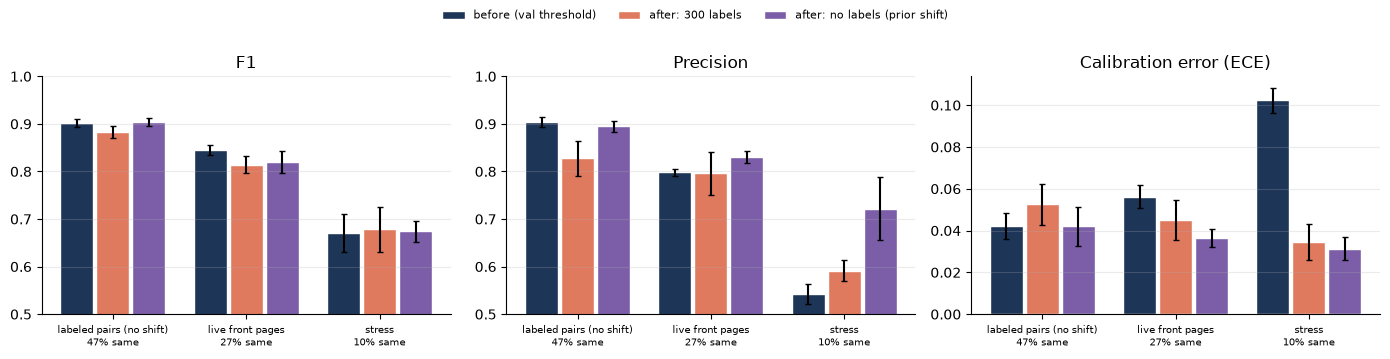

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
xs = np.arange(len(SCEN)); w = 0.27
for ax, met, title in zip(axes, ['f1', 'precision', 'ece'], ['F1', 'Precision', 'Calibration error (ECE)']):
    for k, (when, c) in enumerate([(M_B, C_BEFORE), (M_L, C_AFTER), (M_U, C_ALT)]):
        dd = prior_sum[prior_sum['method'] == when]
        ax.bar(xs + (k - 1) * w, dd[f'{met}_mean'], w * 0.92, yerr=dd[f'{met}_std'], color=c, capsize=2, label=when,
               edgecolor='white', linewidth=1)
    ax.set_xticks(xs); ax.set_xticklabels([f'{s}\n{p:.0%} same' for s, p in SCEN], fontsize=7.5)
    ax.set_title(title); ax.grid(axis='y', alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylim(0.5, 1); axes[1].set_ylim(0.5, 1)
h, l = axes[0].get_legend_handles_labels(); fig.legend(h, l, loc='upper center', ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.savefig(O / 'figures' / 'prior_shift.png', dpi=200); plt.show()

## c. Simulated drift 2: a new language

We train a model on English pairs only, test it on French, and then try to fix it:

* refit the threshold only
* fine-tune on N French pairs + N English pairs (so it does not forget English), 3 seeds
* fine-tune on French only
* full retrain on all pairs (for comparison)

In [7]:
EN_TR, FR_TR = TRAIN[TRAIN.edition == 'en-CA'], TRAIN[TRAIN.edition == 'fr-CA']
EN_VAL = VAL[VAL.edition == 'en-CA']
TEST_BY = {'fr': TEST[TEST.edition == 'fr-CA'], 'en': TEST[TEST.edition == 'en-CA'], 'all': TEST}

def score_model(path, val_for_threshold, ci=True):
    p = Pipeline(BiEncoder(path, Path(path).name)).fit(val_for_threshold)
    out = {'threshold': p.threshold}
    for k, d in TEST_BY.items():
        s = p.raw(d.headline_a, d.headline_b)
        m = evaluate(d.label.values, s, p.threshold)
        out.update({f'f1_{k}': m['f1'], f'precision_{k}': m['precision'], f'recall_{k}': m['recall'], f'pr_auc_{k}': m['pr_auc']})
        if ci and k == 'fr':
            out['f1_fr_lo'], out['f1_fr_hi'] = bootstrap_ci(d.label.values, s, p.threshold)
    return p, out

RUNS_F = O / 'domain_runs.csv'
runs = pd.read_csv(RUNS_F) if RUNS_F.exists() else pd.DataFrame(columns=['run'])
def cached(run):
    return run in set(runs.run)
def record(row):
    global runs
    runs = pd.concat([runs[runs.run != row['run']], pd.DataFrame([row])], ignore_index=True)
    runs.to_csv(RUNS_F, index=False)

EN_PATH = MD / 'minilm_en_only'
if not EN_PATH.exists() or not cached('pre-drift'):
    print('training the English-only pre-drift model')
    info = finetune(BASE_MODEL, EN_TR, EN_VAL, EN_PATH, seed=SEED, epochs=m3.CFG['epochs'], aug_prob=0.0)
    _, res = score_model(EN_PATH, EN_VAL)
    record({'run': 'pre-drift', 'method': 'before: English-only model', 'n_french': 0, 'seed': SEED, **res,
            **{k: v for k, v in info.items() if k != 'path'}})
if not cached('threshold-refit'):
    _, res = score_model(EN_PATH, VAL)
    record({'run': 'threshold-refit', 'method': 'threshold + calibration re-fit', 'n_french': 0, 'seed': SEED, **res,
            'steps': 0, 'minutes': 0.0, 'train_pairs': 0})

N_GRID = [100, 200] if SMOKE else [250, 1000, 4000, len(FR_TR)]
KEEP_FR = MD / 'en_only_plus_fr_all'
for n in N_GRID:
    for seed in SEEDS:
        run = f'incremental-{n}-{seed}'
        path = KEEP_FR if (n == N_GRID[-1] and seed == SEEDS[0]) else MD / f'tmp_{run}'
        if cached(run) and (path != KEEP_FR or path.exists()):   # the kept model is needed in part e
            continue
        fr = FR_TR.sample(n, random_state=seed); en = EN_TR.sample(n, random_state=seed)
        tr = pd.concat([fr, en]).reset_index(drop=True)
        print(run)
        info = finetune(EN_PATH, tr, VAL, path, seed=seed, epochs=2, aug_prob=0.5)
        _, res = score_model(path, VAL, ci=(seed == SEEDS[0]))
        record({'run': run, 'method': 'incremental fine-tune + replay', 'n_french': n, 'seed': seed, **res,
                **{k: v for k, v in info.items() if k != 'path'}})
        if path != KEEP_FR:
            drop_model(path)
if not cached('no-replay'):
    n = N_GRID[-1]; path = MD / 'tmp_no_replay'
    print('incremental, French only (no replay)')
    info = finetune(EN_PATH, FR_TR.sample(n, random_state=SEED).reset_index(drop=True), VAL, path, seed=SEED, epochs=2, aug_prob=0.5)
    _, res = score_model(path, VAL)
    record({'run': 'no-replay', 'method': 'incremental fine-tune, no replay', 'n_french': n, 'seed': SEED, **res,
            **{k: v for k, v in info.items() if k != 'path'}})
    drop_model(path)
if not cached('full-retrain'):
    path = MD / 'tmp_full'
    print('full retrain from the base model on all pairs')
    info = finetune(BASE_MODEL, TRAIN, VAL, path, seed=SEED, epochs=m3.CFG['epochs'], aug_prob=0.5)
    _, res = score_model(path, VAL)
    record({'run': 'full-retrain', 'method': 'full retrain (all pairs, from base)', 'n_french': len(FR_TR), 'seed': SEED, **res,
            **{k: v for k, v in info.items() if k != 'path'}})
    drop_model(path)
if not cached('v1'):
    _, res = score_model(V1_PATH, VAL)
    record({'run': 'v1', 'method': 'v1 (deployed, Milestone 2 full training)', 'n_french': len(FR_TR), 'seed': SEED, **res})

order = ['before: English-only model', 'threshold + calibration re-fit', 'incremental fine-tune + replay',
         'incremental fine-tune, no replay', 'full retrain (all pairs, from base)', 'v1 (deployed, Milestone 2 full training)']
dom = (runs.groupby(['method', 'n_french'])
       .agg(seeds=('seed', 'count'), f1_fr=('f1_fr', 'mean'), f1_fr_sd=('f1_fr', 'std'), f1_en=('f1_en', 'mean'),
            f1_en_sd=('f1_en', 'std'), f1_all=('f1_all', 'mean'), pr_auc_fr=('pr_auc_fr', 'mean'),
            train_pairs=('train_pairs', 'first'), steps=('steps', 'mean'), minutes=('minutes', 'mean'))
       .reset_index())
dom['o'] = dom['method'].map({u: i for i, u in enumerate(order)}); dom = dom.sort_values(['o', 'n_french']).drop(columns='o')
dom.to_csv(O / 'domain_shift.csv', index=False)
dom.round(3)

,method,n_french,seeds,f1_fr,f1_fr_sd,f1_en,f1_en_sd,f1_all,pr_auc_fr,train_pairs,steps,minutes
0,before: English-only model,0.0,1,0.864,NaN,0.907,NaN,0.896,0.945,13416.0,840.0,1.023
7,threshold + calibration re-fit,0.0,1,0.863,NaN,0.908,NaN,0.896,0.945,0.0,0.0,0.000
2,incremental fine-tune + replay,250.0,3,0.855,0.006,0.913,0.002,0.898,0.948,500.0,32.0,0.065
3,incremental fine-tune + replay,1000.0,3,0.863,0.006,0.914,0.007,0.901,0.951,2000.0,126.0,0.197
4,incremental fine-tune + replay,4000.0,3,0.865,0.007,0.921,0.001,0.906,0.951,8000.0,500.0,0.721
5,incremental fine-tune + replay,8491.0,3,0.876,0.010,0.923,0.004,0.911,0.954,16982.0,1062.0,1.535
6,"incremental fine-tune, no replay",8491.0,1,0.872,NaN,0.920,NaN,0.908,0.955,8491.0,532.0,0.842
1,"full retrain (all pairs, from base)",8491.0,1,0.874,NaN,0.921,NaN,0.909,0.956,21907.0,2055.0,3.120
8,"v1 (deployed, Milestone 2 full training)",8491.0,1,0.875,NaN,0.917,NaN,0.906,0.951,NaN,NaN,NaN


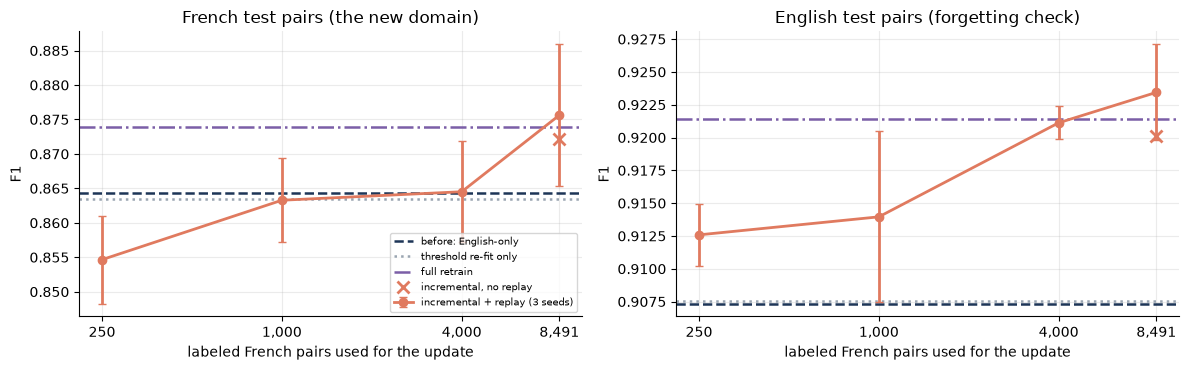

In [8]:
inc = dom[dom['method'] == 'incremental fine-tune + replay']
ref = dom.set_index('method')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, lang, title in [(axes[0], 'fr', 'French test pairs (the new domain)'), (axes[1], 'en', 'English test pairs (forgetting check)')]:
    for u, c, ls, lab in [('before: English-only model', C_BEFORE, '--', 'before: English-only'),
                          ('threshold + calibration re-fit', C_REF, ':', 'threshold re-fit only'),
                          ('full retrain (all pairs, from base)', C_ALT, '-.', 'full retrain')]:
        ax.axhline(ref.loc[u, f'f1_{lang}'], color=c, ls=ls, lw=1.8, label=lab)
    ax.errorbar(inc.n_french, inc[f'f1_{lang}'], yerr=inc[f'f1_{lang}_sd'].fillna(0), color=C_AFTER, marker='o', ms=6, lw=2,
                capsize=3, label='incremental + replay (3 seeds)')
    if 'incremental fine-tune, no replay' in ref.index:
        nr = ref.loc['incremental fine-tune, no replay']
        ax.plot([nr.n_french], [nr[f'f1_{lang}']], color=C_AFTER, marker='x', ms=9, mew=2, ls='none', label='incremental, no replay')
    ax.set_xscale('log'); ax.set_xticks(N_GRID); ax.set_xticklabels([f'{n:,}' for n in N_GRID]); ax.minorticks_off()
    ax.set(title=title, xlabel='labeled French pairs used for the update', ylabel='F1')
    ax.grid(alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.savefig(O / 'figures' / 'domain_shift.png', dpi=200); plt.show()

## d. Updating v1 with new labels

We fine-tune v1 on the May to Jul pairs (plus the same number of old training pairs) and test on Aug to Oct. We also check card
ARI and validation PR-AUC (to see if it forgot old data). 3 seeds.

In [9]:
RUNS_S = O / 'stream_runs.csv'
sruns = pd.read_csv(RUNS_S) if RUNS_S.exists() else pd.DataFrame(columns=['run'])
pages_future = front_pages(min_date='20260801000000')
if SMOKE:
    pages_future = pages_future[:10]

def score_stream(path, name):
    p = Pipeline(BiEncoder(path, name)).fit(VAL)
    out = {'threshold': p.threshold}
    for k, d in [('future', FUTURE), ('future_en', FUTURE[FUTURE.edition == 'en-CA']), ('future_fr', FUTURE[FUTURE.edition == 'fr-CA'])]:
        s = p.raw(d.headline_a, d.headline_b); m = evaluate(d.label.values, s, p.threshold)
        out.update({f'f1_{k}': m['f1'], f'pr_auc_{k}': m['pr_auc']})
        if k == 'future':
            out['precision_future'], out['recall_future'] = m['precision'], m['recall']
            out['f1_future_lo'], out['f1_future_hi'] = bootstrap_ci(d.label.values, s, p.threshold)
    s = p.raw(VAL.headline_a, VAL.headline_b)
    out['pr_auc_val'] = evaluate(VAL.label.values, s, p.threshold)['pr_auc']
    out['card_ARI_future'], out['exact_cards_future'] = grouping(p, pages_future)
    return out

def srecord(row):
    global sruns
    sruns = pd.concat([sruns[sruns.run != row['run']], pd.DataFrame([row])], ignore_index=True); sruns.to_csv(RUNS_S, index=False)

if 'v1' not in set(sruns.run):
    srecord({'run': 'v1', 'model': 'before: v1 (deployed)', 'seed': SEED, **score_stream(V1_PATH, 'v1')})
KEEP_V1U = MD / 'v1_updated_mayjul'
for seed in SEEDS:
    run = f'update-{seed}'
    path = KEEP_V1U if seed == SEEDS[0] else MD / f'tmp_{run}'
    if run in set(sruns.run) and (path != KEEP_V1U or path.exists()):   # the kept model is needed in part e
        continue
    replay = TRAIN.sample(len(ADAPT_WIN), random_state=seed)
    tr = pd.concat([ADAPT_WIN.drop(columns=['s']), replay]).reset_index(drop=True)
    print(run)
    info = finetune(V1_PATH, tr, VAL, path, seed=seed, epochs=2, aug_prob=0.5)
    srecord({'run': run, 'model': 'after: v1 + May-Jul update', 'seed': seed, **score_stream(path, run),
             **{k: v for k, v in info.items() if k != 'path'}})
    if path != KEEP_V1U:
        drop_model(path)

cols = ['f1_future', 'precision_future', 'recall_future', 'pr_auc_future', 'f1_future_en', 'f1_future_fr', 'card_ARI_future',
        'exact_cards_future', 'pr_auc_val']
stream = sruns.groupby('model', sort=False)[cols].agg(['mean', 'std'])
stream.columns = [f'{a}_{b}' for a, b in stream.columns]
stream = stream.reset_index(); stream.to_csv(O / 'stream_update.csv', index=False)
stream[['model'] + [f'{c}_mean' for c in cols] + ['f1_future_std']].round(4)

,model,f1_future_mean,precision_future_mean,recall_future_mean,pr_auc_future_mean,f1_future_en_mean,f1_future_fr_mean,card_ARI_future_mean,exact_cards_future_mean,pr_auc_val_mean,f1_future_std
0,before: v1 (deployed),0.9033,0.9078,0.8988,0.9579,0.9050,0.8984,0.7491,0.6150,0.9443,NaN
1,after: v1 + May-Jul update,0.8840,0.9046,0.8644,0.9554,0.8924,0.8582,0.7608,0.6317,0.9386,0.0037


## e. Latency and size

CPU latency per front page (same as Milestone 2) for the before and after models. The models are measured in turns so they all
get the same conditions.

In [10]:
m3.DEVICE = 'cpu'
lat_pages = [h for h, _, _ in pages_all if len(h) >= 2]
heads = pd.unique(pd.concat([TEST.headline_a, TEST.headline_b])).tolist()[:2000]
proc = psutil.Process()
del v1                                            # free the MPS copy before loading the CPU copies
LAT_MODELS = {'v1 (before)': V1_PATH, 'v1 + May-Jul update (after, 4.3d)': KEEP_V1U,
              'English-only (before, 4.3c)': EN_PATH, 'English-only + all French (after, 4.3c)': KEEP_FR}
rss0 = proc.memory_info().rss
pipes = {}
for name, path in LAT_MODELS.items():
    pipes[name] = Pipeline(BiEncoder(path, name), name=name)
rss_per_model = (proc.memory_info().rss - rss0) / len(pipes) / 1e9
lat = interleaved_latency(pipes, lat_pages, rounds=3 if SMOKE else 10, per_round=10 if SMOKE else 20)
rows = []
for name, p in pipes.items():
    ts = []
    for _ in range(3):
        t0 = time.perf_counter(); p.scorer.embed(heads, batch_size=64); ts.append(len(heads) / (time.perf_counter() - t0))
    rows.append({'model': name, 'device': 'cpu', **lat[name], 'headlines_per_s': float(np.median(ts)),
                 'disk_MB': dir_mb(LAT_MODELS[name]), 'params_M': sum(q.numel() for q in p.scorer.model.parameters()) / 1e6,
                 'rss_GB_per_model': rss_per_model})
del pipes
m3.DEVICE = TRAIN_DEVICE
eff = pd.DataFrame(rows); eff.to_csv(O / 'latency_size.csv', index=False)
m2_lat = (M2.get('page_latency') or {}).get('p50_ms')
print('Milestone 2 v1 CPU page latency p50 (same machine type):', m2_lat, 'ms')
json.dump({'hardware': HW, 'latency_device': 'cpu', 'm2_v1_page_p50_ms': m2_lat}, open(O / 'hardware.json', 'w'), indent=2)
eff.round(2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 21681.90it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10996.34it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 18234.91it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17236.63it/s]

Milestone 2 v1 CPU page latency p50 (same machine type): 16.23 ms


,model,device,p50_ms,p90_ms,n_pages,headlines_per_s,disk_MB,params_M,rss_GB_per_model
0,v1 (before),cpu,26.85,30.14,200,754.00,487.73,117.65,0.29
1,"v1 + May-Jul update (after, 4.3d)",cpu,26.76,30.31,200,737.27,487.73,117.65,0.29
2,"English-only (before, 4.3c)",cpu,26.61,30.13,200,739.52,487.73,117.65,0.29
3,"English-only + all French (after, 4.3c)",cpu,26.51,30.32,200,742.91,487.73,117.65,0.29


In [11]:
# one-table summary for the report
dm = dom.set_index(['method', 'n_french'])
pre = dm.loc['before: English-only model'].iloc[0]; full = dm.loc['full retrain (all pairs, from base)'].iloc[0]
inc_all = dm.loc['incremental fine-tune + replay'].iloc[-1]; inc_1k = dm.loc['incremental fine-tune + replay'].iloc[min(1, len(N_GRID) - 1)]
ps = prior_sum.set_index(['scenario', 'method'])
st = stream.set_index('model'); e = eff.set_index('model')
summary = pd.DataFrame([
    {'experiment': f'b: label shift ({scen})', 'metric': f'F1 Aug-Oct, {pi:.0%} same', 'before': ps.loc[(scen, M_B), 'f1_mean'],
     'after': ps.loc[(scen, m), 'f1_mean'], 'update cost': cost, 'latency/size change': 'none'}
    for scen, pi in SCEN[1:] for m, cost in [(M_L, '300 labels, no training'), (M_U, 'no labels, no training')]] + [
    {'experiment': 'c: new domain (French)', 'metric': 'French test F1', 'before': pre.f1_fr, 'after': inc_1k.f1_fr,
     'update cost': f'{int(inc_1k.train_pairs)} pairs, {inc_1k.minutes:.1f} min', 'latency/size change': 'none (same architecture)'},
    {'experiment': 'c: new domain (French)', 'metric': 'French test F1', 'before': pre.f1_fr, 'after': inc_all.f1_fr,
     'update cost': f'{int(inc_all.train_pairs)} pairs, {inc_all.minutes:.1f} min', 'latency/size change': 'none (same architecture)'},
    {'experiment': 'c: full retrain reference', 'metric': 'French test F1', 'before': pre.f1_fr, 'after': full.f1_fr,
     'update cost': f'{int(full.train_pairs)} pairs, {full.minutes:.1f} min', 'latency/size change': 'none (same architecture)'},
    {'experiment': 'd: real stream update', 'metric': 'F1 Aug-Oct', 'before': st.loc['before: v1 (deployed)', 'f1_future_mean'],
     'after': st.loc['after: v1 + May-Jul update', 'f1_future_mean'], 'update cost': f'{2 * len(ADAPT_WIN)} pairs',
     'latency/size change': f"p50 {e.loc['v1 (before)', 'p50_ms']:.1f} -> {e.loc['v1 + May-Jul update (after, 4.3d)', 'p50_ms']:.1f} ms"},
    {'experiment': 'd: real stream update', 'metric': 'card ARI Aug-Oct', 'before': st.loc['before: v1 (deployed)', 'card_ARI_future_mean'],
     'after': st.loc['after: v1 + May-Jul update', 'card_ARI_future_mean'], 'update cost': '', 'latency/size change': ''},
])
summary['change'] = summary.after - summary.before
summary.to_csv(O / 'adaptation_summary.csv', index=False)
summary.round(3)

,experiment,metric,before,after,update cost,latency/size change,change
0,b: label shift (live front pages),"F1 Aug-Oct, 27% same",0.845,0.814,"300 labels, no training",none,-0.031
1,b: label shift (live front pages),"F1 Aug-Oct, 27% same",0.845,0.819,"no labels, no training",none,-0.026
2,b: label shift (stress),"F1 Aug-Oct, 10% same",0.670,0.678,"300 labels, no training",none,0.008
3,b: label shift (stress),"F1 Aug-Oct, 10% same",0.670,0.674,"no labels, no training",none,0.004
4,c: new domain (French),French test F1,0.864,0.863,"2000 pairs, 0.2 min",none (same architecture),-0.001
5,c: new domain (French),French test F1,0.864,0.876,"16982 pairs, 1.5 min",none (same architecture),0.011
6,c: full retrain reference,French test F1,0.864,0.874,"21907 pairs, 3.1 min",none (same architecture),0.010
7,d: real stream update,F1 Aug-Oct,0.903,0.884,2786 pairs,p50 26.9 -> 26.8 ms,-0.019
8,d: real stream update,card ARI Aug-Oct,0.749,0.761,,,0.012


## Results summary

* **a.** No trigger fired. Only the language mix changed (June has no French pairs). F1 never went below validation.
* **b.** With fewer same-story pairs, precision drops a lot (0.90 to 0.54 at 10%). Adjusting the calibration without labels brings
  precision back to 0.72 and ECE from 0.10 to 0.03. F1 does not really change.
* **c.** The English-only model already does OK on French (0.864). Fine-tuning on all French pairs + English gives 0.876, the same
  as a full retrain (0.874) in half the time. 250 or 1,000 French pairs did not help. The differences are small (inside the
  confidence intervals).
* **d.** Updating v1 on May to Jul made F1 worse (0.903 to 0.884), so we would not deploy it. We should only retrain when a
  trigger fires.
* **e.** Latency and size do not change (about 27 ms per page, 488 MB) because the architecture is the same.